In [3]:

!pip install -q plotly seaborn pandas numpy matplotlib pyspark scipy
print("✅ Libraries installed successfully!")

✅ Libraries installed successfully!


In [4]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, sum as spark_sum
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("Practical3_CustomerFeedback") \
    .getOrCreate()
print("✅ Spark session created successfully!")

✅ Spark session created successfully!


In [5]:
from google.colab import files
import zipfile
import os
uploaded = files.upload()
zip_filename = "customerfeedback_cleaned.zip"
with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall("/content/customerfeedback_data")
print("✅ Cleaned dataset extracted successfully!")
print("Extracted files:")
print(os.listdir("/content/customerfeedback_data"))


Saving customerfeedback_cleaned.zip to customerfeedback_cleaned.zip
✅ Cleaned dataset extracted successfully!
Extracted files:
['customerfeedback_cleaned.parquet']


In [6]:

file_path = "/content/customerfeedback_data/customerfeedback_cleaned.parquet"
df_spark = spark.read.parquet(file_path)
print("✅ Dataset loaded successfully!")
print(f"Total rows: {df_spark.count():,}")
print(f"Number of columns: {len(df_spark.columns)}")
df_spark.printSchema()
df_spark.show(5, truncate=False)

✅ Dataset loaded successfully!
Total rows: 250,000
Number of columns: 6
root
 |-- customer: struct (nullable = true)
 |    |-- age: long (nullable = true)
 |    |-- id: string (nullable = true)
 |    |-- location: string (nullable = true)
 |    |-- loyalty_years: long (nullable = true)
 |    |-- name: string (nullable = true)
 |-- device_type: string (nullable = true)
 |-- feedback: struct (nullable = true)
 |    |-- product_category: string (nullable = true)
 |    |-- rating: long (nullable = true)
 |    |-- sentiment: double (nullable = true)
 |    |-- store_location: string (nullable = true)
 |    |-- text: string (nullable = true)
 |-- feedback_id: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- timestamp: string (nullable = true)

+---------------------------------------------------------------------------+-----------+----------------------------------------------------------------------------------+------------------------------------+----------+------------

In [7]:

from pyspark.sql.functions import col, to_timestamp
df_flat = df_spark.select(
    col("feedback_id"),
    col("customer.id").alias("customer_id"),
    col("customer.name").alias("customer_name"),
    col("customer.age").alias("customer_age"),
    col("customer.location").alias("customer_location"),
    col("customer.loyalty_years").alias("loyalty_years"),
    col("feedback.text").alias("feedback_text"),
    col("feedback.rating").alias("feedback_rating"),
    col("feedback.sentiment").alias("sentiment_score"),
    col("feedback.product_category").alias("product_category"),
    col("feedback.store_location").alias("store_location"),
    col("device_type"),
    col("platform"),
    to_timestamp(col("timestamp")).alias("timestamp"))
print("Dataset flattened successfully!")
print("Total rows:", df_flat.count())
print("Number of columns:", len(df_flat.columns))
df_flat.printSchema()
df_flat.show(5, truncate=False)

Dataset flattened successfully!
Total rows: 250000
Number of columns: 14
root
 |-- feedback_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- customer_name: string (nullable = true)
 |-- customer_age: long (nullable = true)
 |-- customer_location: string (nullable = true)
 |-- loyalty_years: long (nullable = true)
 |-- feedback_text: string (nullable = true)
 |-- feedback_rating: long (nullable = true)
 |-- sentiment_score: double (nullable = true)
 |-- product_category: string (nullable = true)
 |-- store_location: string (nullable = true)
 |-- device_type: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)

+------------------------------------+------------------------------------+---------------+------------+-----------------+-------------+-----------------------------------------+---------------+---------------+----------------+----------------+-----------+----------+-------------------+
|feedback_

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
df_sample = df_flat.orderBy("feedback_id").limit(50000)
df = df_sample.toPandas()
print("Dataset converted to Pandas successfully!")
print("Total sampled rows:", len(df))
print("Number of columns:", len(df.columns))
display(df.head())
display(df.describe())


Dataset converted to Pandas successfully!
Total sampled rows: 50000
Number of columns: 14


,feedback_id,customer_id,customer_name,customer_age,customer_location,loyalty_years,feedback_text,feedback_rating,sentiment_score,product_category,store_location,device_type,platform,timestamp
0,0000cb1f-e088-4f08-9472-7794696c43e1,f1fc4e71-542d-4c79-acce-5a4c82616f5f,James Simpson,47,"Phoenix, AZ",2,Super fast shipping and great packaging.,4,0.392,Clothing,"Dallas, TX",Tablet,Phone,2021-04-25 08:01:00
1,000107c8-806f-4a10-b109-897964ed8da1,b52d36d9-6e40-48d1-92ce-d3716e71b32f,Sydney Graves,62,"Philadelphia, PA",4,"Poor customer service, very disappointed.",1,-0.389,Groceries,"Los Angeles, CA",Android,In-Store,2022-10-17 15:06:00
2,00012e98-7155-4daa-a8db-12275c576c69,3cc006d3-9cb3-4e88-93e0-bce5d93c3cf3,Andrew Clark,22,"Phoenix, AZ",2,"Never received my order, very frustrated.",1,-0.640,Clothing,"Dallas, TX",Android,Web,2021-10-20 13:05:00
3,00013cd4-9658-4bc4-a302-75843cd69f37,51136cdb-c71c-4958-807f-291f1c13ae34,Erica Jackson DDS,36,"Miami, FL",3,Super fast shipping and great packaging.,4,0.676,Sports,"New York, NY",Web Browser,Email,2026-01-09 17:42:00
4,00016d53-eaa6-4d9f-bdd9-75fcecb7adfb,e0e7d573-dda5-4461-83c8-b7bb8cd66d8a,Tiffany Hicks,20,"Denver, CO",1,Amazing quality and great prices.,5,0.709,Clothing,"San Diego, CA",Web Browser,Phone,2024-12-05 16:26:00


,customer_age,loyalty_years,feedback_rating,sentiment_score,timestamp
count,50000.00000,50000.000000,50000.00000,50000.000000,50000
mean,41.61418,2.507500,3.00368,0.001268,2023-10-01 01:16:54.061199872
min,0.00000,0.000000,1.00000,-1.000000,2021-01-01 08:46:00
25%,32.00000,0.000000,2.00000,-0.496000,2022-05-20 19:49:45
50%,41.00000,2.000000,3.00000,0.000000,2023-09-29 21:36:00
75%,52.00000,4.000000,4.00000,0.500000,2025-02-11 10:06:15
max,104.00000,32.000000,5.00000,1.000000,2026-06-30 21:29:00
std,14.76927,2.977691,1.32122,0.576779,NaN


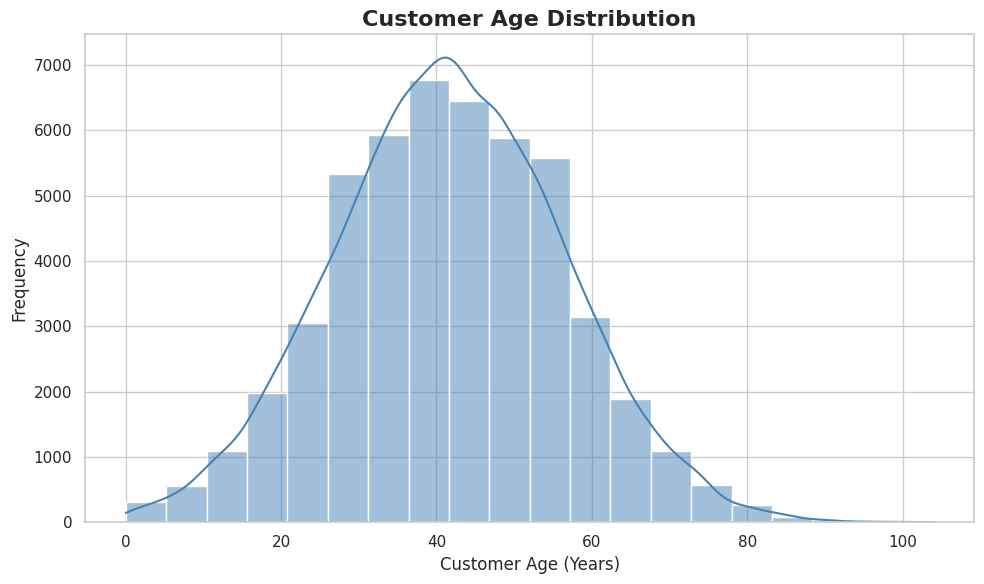

In [9]:
########## PART##########
#########CUSTOMER AGE DISTRIBUTION ##########
import matplotlib.pyplot as plt
import seaborn as sns
# Set visualization style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
# Create histogram with frequency density curve
sns.histplot(
    data=df,
    x="customer_age",
    bins=20,
    kde=True,
    color="steelblue",
    edgecolor="white"
)
# Add titles and labels
plt.title(
    "Customer Age Distribution",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Customer Age (Years)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()


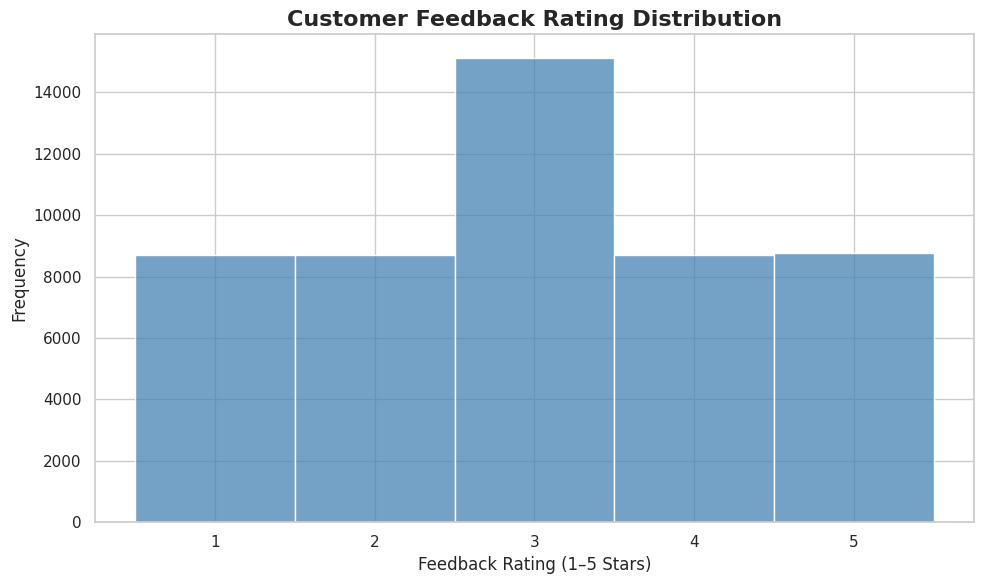

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="feedback_rating",
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    color="steelblue",
    edgecolor="white"
)
# Add chart title and labels
plt.title(
    "Customer Feedback Rating Distribution",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Feedback Rating (1–5 Stars)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
# Display individual rating values
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

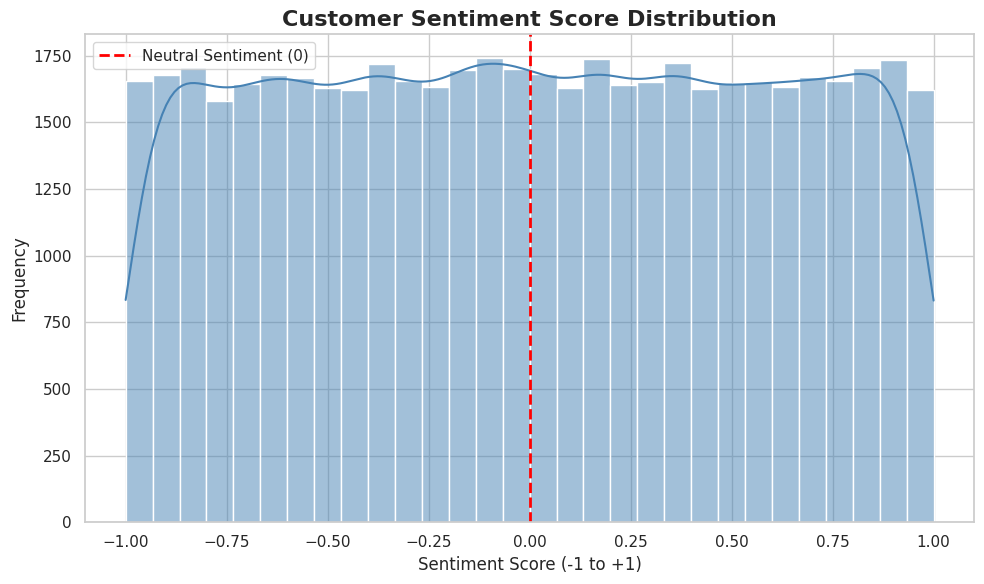

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="sentiment_score",
    bins=30,
    kde=True,
    color="steelblue",
    edgecolor="white")
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Neutral Sentiment (0)")
plt.title(
    "Customer Sentiment Score Distribution",
    fontsize=16,
    fontweight="bold")
plt.xlabel("Sentiment Score (-1 to +1)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()


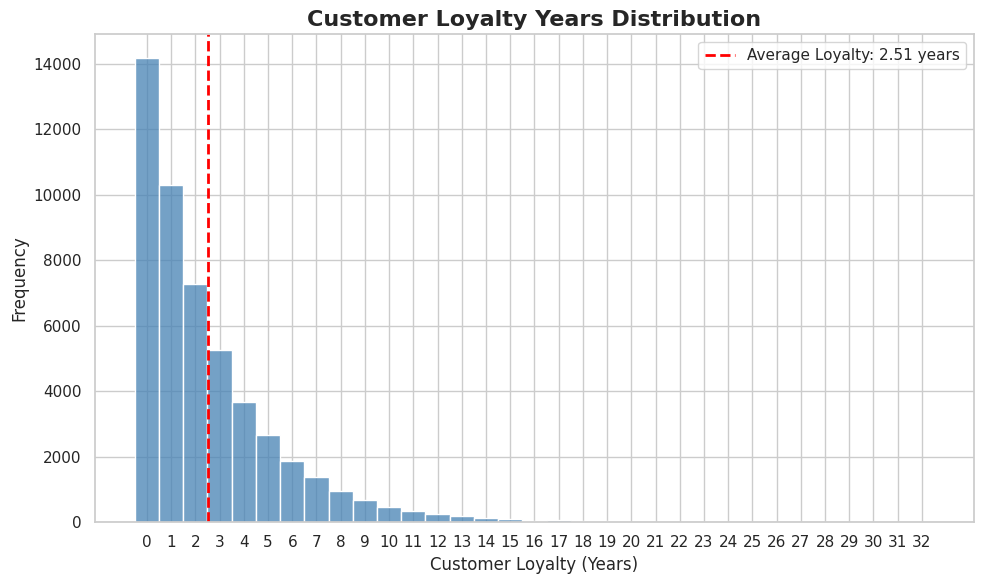

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Set visualization style
sns.set_theme(style="whitegrid")
# Create figure
plt.figure(figsize=(10, 6))
# Create histogram with discrete loyalty year intervals
sns.histplot(
    data=df,
    x="loyalty_years",
    discrete=True,
    color="steelblue",
    edgecolor="white")
mean_loyalty = df["loyalty_years"].mean()
plt.axvline(
    x=mean_loyalty,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Average Loyalty: {mean_loyalty:.2f} years")
plt.title(
    "Customer Loyalty Years Distribution",
    fontsize=16,
    fontweight="bold")
plt.xlabel("Customer Loyalty (Years)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.xticks(
    np.arange(
        df["loyalty_years"].min(),
        df["loyalty_years"].max() + 1,1 ))
plt.legend()
plt.tight_layout()
plt.show()

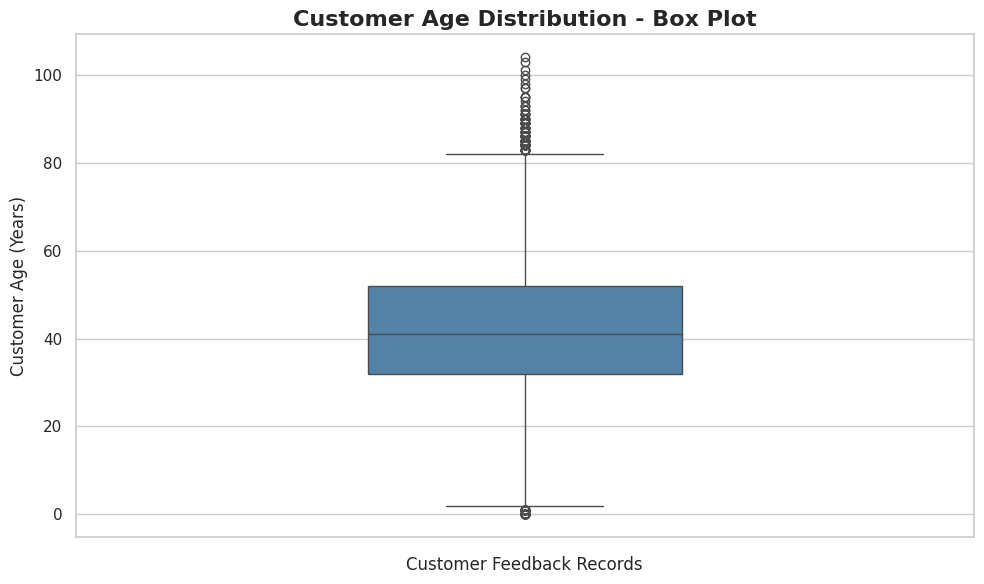

CUSTOMER AGE OUTLIER ANALYSIS
-----------------------------
Minimum Age: 0
Maximum Age: 104
Median Age: 41.00
Q1: 32.00
Q3: 52.00
IQR: 20.00
Lower Bound: 2.00
Upper Bound: 82.00
Potential Outliers: 235


In [13]:
########## PART C: BOX PLOTS AND OUTLIER DETECTION ##########
import matplotlib.pyplot as plt
import seaborn as sns
# Set visualization style
sns.set_theme(style="whitegrid")
# Create figure
plt.figure(figsize=(10, 6))
# Create box plot
sns.boxplot(
    data=df,
    y="customer_age",
    color="steelblue",
    width=0.35,
    showfliers=True)
plt.title(
    "Customer Age Distribution - Box Plot",
    fontsize=16,
    fontweight="bold")
plt.ylabel("Customer Age (Years)", fontsize=12)
plt.xlabel("Customer Feedback Records", fontsize=12)
plt.tight_layout()
plt.show()
# Calculate summary statistics
Q1 = df["customer_age"].quantile(0.25)
Q3 = df["customer_age"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[
    (df["customer_age"] < lower_bound) |
    (df["customer_age"] > upper_bound)]
print("CUSTOMER AGE OUTLIER ANALYSIS")
print("-----------------------------")
print(f"Minimum Age: {df['customer_age'].min()}")
print(f"Maximum Age: {df['customer_age'].max()}")
print(f"Median Age: {df['customer_age'].median():.2f}")
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Potential Outliers: {len(outliers)}")


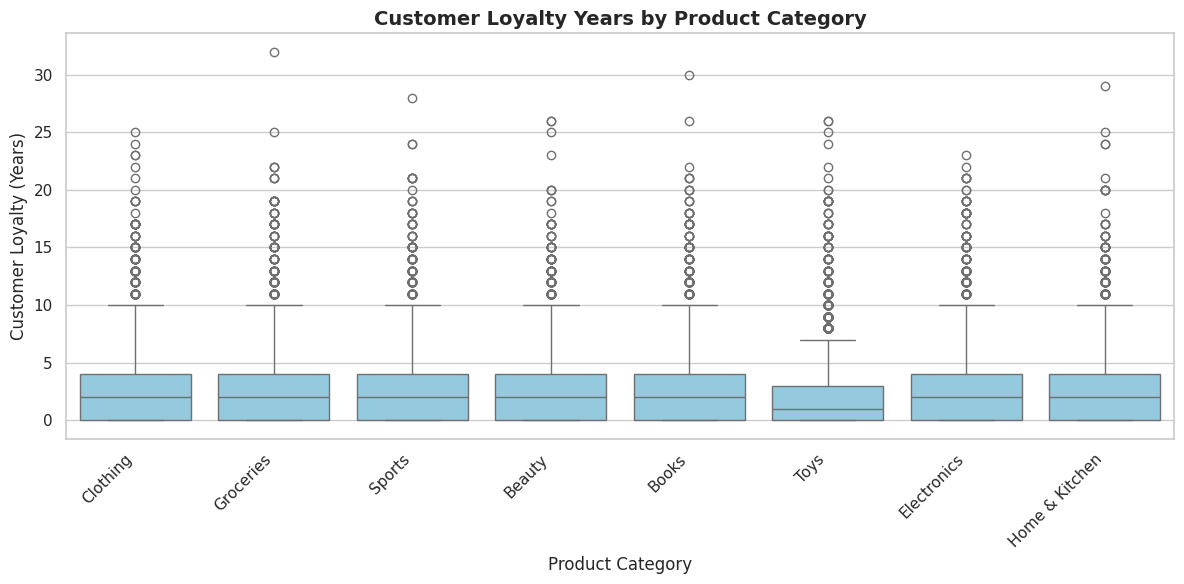

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
# Set visualization style
sns.set_theme(style="whitegrid")
# Create figure
plt.figure(figsize=(12, 6))
# Create box plot
sns.boxplot(
    x="product_category",
    y="loyalty_years",
    data=df,
    color="skyblue")
# Add titles and labels
plt.title(
    "Customer Loyalty Years by Product Category",
    fontsize=14,
    fontweight="bold")
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Customer Loyalty (Years)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


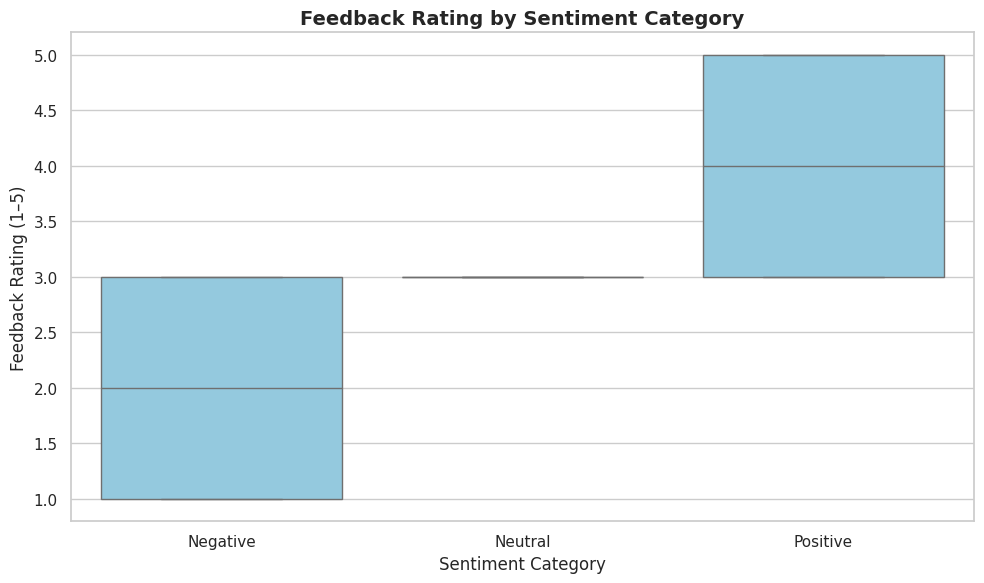

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Create sentiment categories based on sentiment score
df["sentiment_category"] = pd.cut(
    df["sentiment_score"],
    bins=[-float("inf"), -0.05, 0.05, float("inf")],
    labels=["Negative", "Neutral", "Positive"])
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="sentiment_category",
    y="feedback_rating",
    order=["Negative", "Neutral", "Positive"],
    color="skyblue")
plt.title("Feedback Rating by Sentiment Category", fontsize=14, fontweight="bold")
plt.xlabel("Sentiment Category")
plt.ylabel("Feedback Rating (1–5)")
plt.tight_layout()
plt.show()


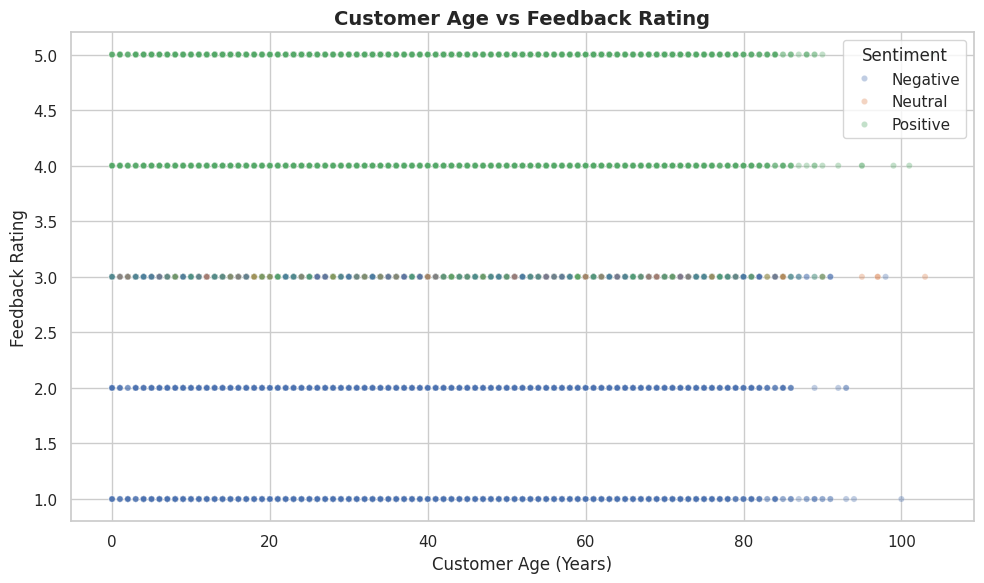

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="customer_age",
    y="feedback_rating",
    hue="sentiment_category",
    alpha=0.35,
    s=20)
plt.title("Customer Age vs Feedback Rating", fontsize=14, fontweight="bold")
plt.xlabel("Customer Age (Years)")
plt.ylabel("Feedback Rating")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [18]:
import plotly.express as px
# Use a smaller sample for smooth interactive performance
df_3d = df.sample(n=min(5000, len(df)), random_state=42)
fig = px.scatter_3d(
    df_3d,
    x="customer_age",
    y="loyalty_years",
    z="feedback_rating",
    color="sentiment_category",
    title="3D Customer Feedback Analysis",
    labels={
        "customer_age": "Customer Age",
        "loyalty_years": "Loyalty Years",
        "feedback_rating": "Feedback Rating" }, opacity=0.65)
fig.update_layout(height=650)
fig.show()

In [19]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
# Create customer age groups
df["age_group"] = pd.cut(
    df["customer_age"],
    bins=[-1, 17, 25, 35, 45, 55, 65, float("inf")],
    labels=["0-17", "18-25", "26-35", "36-45",
            "46-55", "56-65", "66+"])
# Calculate average rating for each age and loyalty combination
surface_data = df.pivot_table(
    index="age_group",
    columns="loyalty_years",
    values="feedback_rating",
    aggfunc="mean",
    observed=False)
fig = go.Figure(
    data=[
        go.Surface(
            z=surface_data.to_numpy(dtype=float),
            x=surface_data.columns.to_numpy(),
            y=np.arange(len(surface_data.index)),
            colorscale="Viridis",
            colorbar=dict(title="Avg Rating") ) ])
fig.update_layout(
    title="Average Feedback Rating by Age Group and Loyalty Years",
    scene=dict(
        xaxis_title="Loyalty Years",
        yaxis=dict(
            title="Age Group",
            tickvals=list(range(len(surface_data.index))),
            ticktext=[str(x) for x in surface_data.index]
        ),
        zaxis_title="Average Feedback Rating"), height=650)
fig.show()

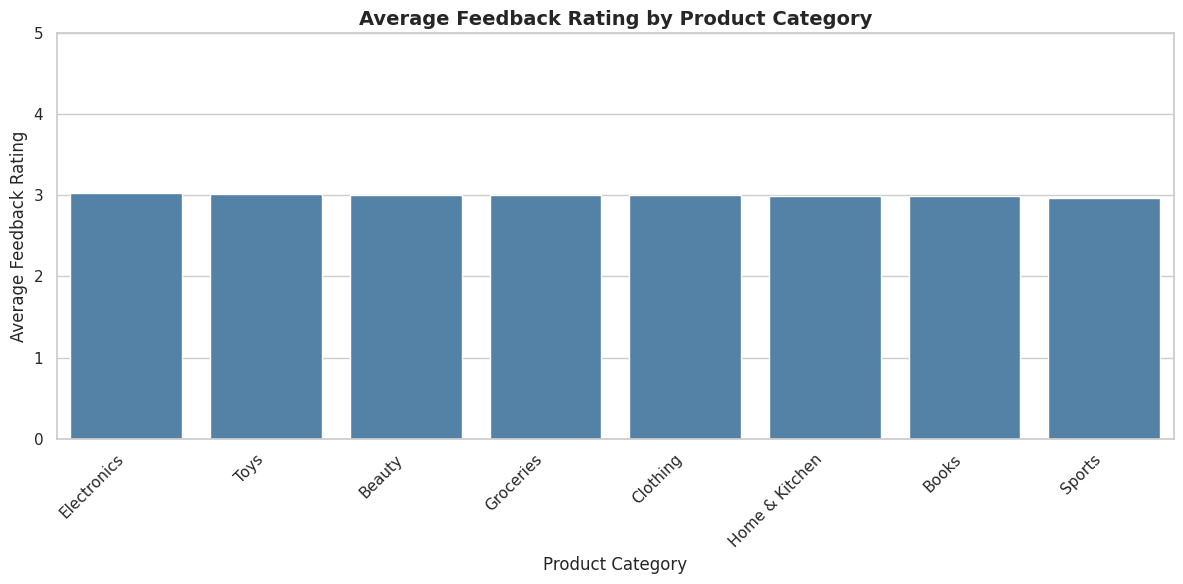

,product_category,feedback_rating
0,Electronics,3.027556
1,Toys,3.021856
2,Beauty,3.006321
3,Groceries,3.005466
4,Clothing,2.999344
5,Home & Kitchen,2.999207
6,Books,2.999049
7,Sports,2.969663


In [20]:
category_rating = (
    df.groupby("product_category")["feedback_rating"]
    .mean()
    .sort_values(ascending=False)
    .reset_index())
plt.figure(figsize=(12, 6))
sns.barplot(
    data=category_rating,
    x="product_category",
    y="feedback_rating",
    color="steelblue")
plt.title("Average Feedback Rating by Product Category",
          fontsize=14, fontweight="bold")
plt.xlabel("Product Category")
plt.ylabel("Average Feedback Rating")
plt.ylim(0, 5)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(category_rating)

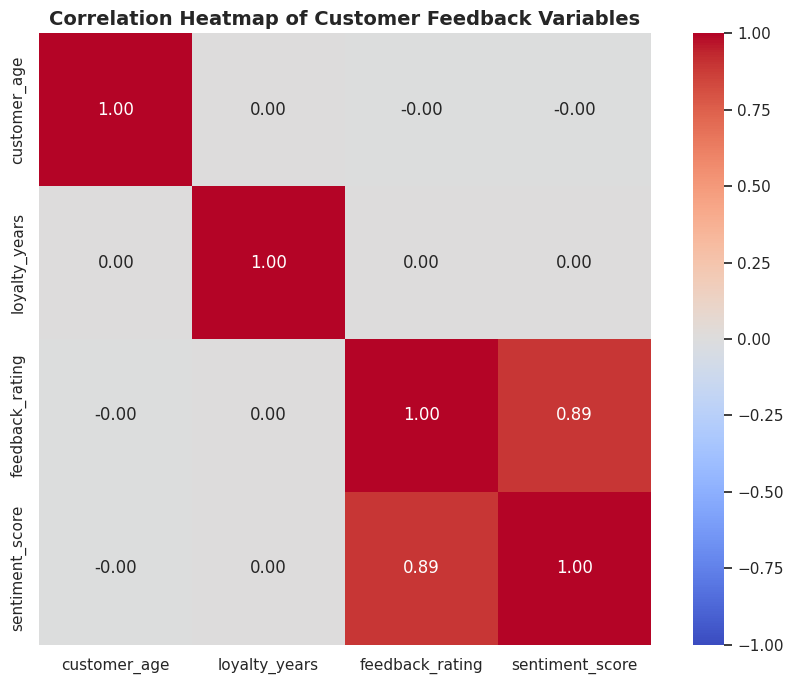

In [21]:
numeric_columns = [
    "customer_age",
    "loyalty_years",
    "feedback_rating",
    "sentiment_score"]
correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True)
plt.title("Correlation Heatmap of Customer Feedback Variables",fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [22]:
print("=" * 55)
print("CUSTOMER FEEDBACK - PRACTICAL 3 SUMMARY")
print("=" * 55)
print(f"Records analysed: {len(df):,}")
print(f"Average customer age: {df['customer_age'].mean():.2f} years")
print(f"Average loyalty duration: {df['loyalty_years'].mean():.2f} years")
print(f"Average feedback rating: {df['feedback_rating'].mean():.2f} / 5")
print(f"Average sentiment score: {df['sentiment_score'].mean():.4f}")
print("\nFeedback Rating Distribution:")
print(df["feedback_rating"].value_counts().sort_index())
print("\nSentiment Category Distribution:")
print(df["sentiment_category"].value_counts())
print("\nAverage Rating by Product Category:")
display(category_rating)
print("\nCorrelation Matrix:")
display(correlation_matrix)

CUSTOMER FEEDBACK - PRACTICAL 3 SUMMARY
Records analysed: 50,000
Average customer age: 41.61 years
Average loyalty duration: 2.51 years
Average feedback rating: 3.00 / 5
Average sentiment score: 0.0013

Feedback Rating Distribution:
feedback_rating
1     8690
2     8698
3    15130
4     8702
5     8780
Name: count, dtype: int64

Sentiment Category Distribution:
sentiment_category
Negative    23738
Positive    23698
Neutral      2564
Name: count, dtype: int64

Average Rating by Product Category:


,product_category,feedback_rating
0,Electronics,3.027556
1,Toys,3.021856
2,Beauty,3.006321
3,Groceries,3.005466
4,Clothing,2.999344
5,Home & Kitchen,2.999207
6,Books,2.999049
7,Sports,2.969663



Correlation Matrix:


,customer_age,loyalty_years,feedback_rating,sentiment_score
customer_age,1.000000,0.000382,-0.002504,-0.000801
loyalty_years,0.000382,1.000000,0.001320,0.000448
feedback_rating,-0.002504,0.001320,1.000000,0.894291
sentiment_score,-0.000801,0.000448,0.894291,1.000000
